# FlashAttention in Needle: build, test and benchmark on a GPU

This notebook builds the Needle backends (CPU and CUDA), runs the FlashAttention test suite on
the GPU, runs the two benchmarks, and draws the figures.

**Before running**

1. `Runtime > Change runtime type > T4 GPU`.
2. Have `needle-flash-attention.zip` (the project folder, zipped) on your computer. The second
   cell asks for it.

Run the cells top to bottom. The whole notebook takes a few minutes.

## 1. Check the GPU

In [1]:
!nvidia-smi --query-gpu=name,memory.total --format=csv

name, memory.total [MiB]
Tesla T4, 15360 MiB


## 2. Get the code

Uploads and unpacks `needle-flash-attention.zip` into `/content`. If the folder is already
there (for example after re-running this cell) nothing is uploaded again; delete
`/content/needle-flash-attention` first to replace it with a newer zip.

In [2]:
import os

REPO = "/content/needle-flash-attention"

if not os.path.isdir(REPO):
    os.chdir("/content")
    zips = [f for f in os.listdir(".") if f.startswith("needle-flash-attention") and f.endswith(".zip")]
    if not zips:
        from google.colab import files
        zips = list(files.upload())  # choose needle-flash-attention.zip
    !unzip -q -o "{zips[0]}" -d /content

os.chdir(REPO)
print("working directory:", os.getcwd())
!ls

Saving needle-flash-attention.zip to needle-flash-attention.zip
working directory: /content/needle-flash-attention
apps			CMakeLists.txt		msvc_compat.h  src
build_windows.bat	colab_benchmarks.ipynb	python	       tests
build_windows_cuda.bat	Makefile		README.md


## 3. Build the backends

`make` runs CMake, which builds the CPU backend and, when it finds the CUDA toolkit, the CUDA
backend. Look for `Found cuda, building cuda backend` in the output. Compiling the CUDA
backend is the slow part and can take several minutes: the line
`Building NVCC (Device) object ...` stays on screen while `nvcc` works. The last line printed
by this cell must say that the cuda backend is enabled and has the backward kernel.

In [3]:
!pip install -q pybind11
!make clean
!make
!python -c "import sys; sys.path.append('python'); import needle as ndl; d = ndl.cuda(); print('cuda backend enabled:', d.enabled(), '| forward kernel:', hasattr(d, 'flash_attention_fwd'), '| backward kernel:', hasattr(d, 'flash_attention_bwd'))"

rm -rf build python/needle/backend_ndarray/ndarray_backend*.so
CMake Deprecation Warning at CMakeLists.txt:1 (cmake_minimum_required):
  Compatibility with CMake < 3.10 will be removed from a future version of
  CMake.

  Update the VERSION argument <min> value.  Or, use the <min>...<max> syntax
  to tell CMake that the project requires at least <min> but has been updated
  to work with policies introduced by <max> or earlier.


-- The C compiler identification is GNU 13.3.0
-- The CXX compiler identification is GNU 13.3.0
-- Detecting C compiler ABI info
-- Detecting C compiler ABI info - done
-- Check for working C compiler: /usr/bin/cc - skipped
-- Detecting C compile features
-- Detecting C compile features - done
-- Detecting CXX compiler ABI info
-- Detecting CXX compiler ABI info - done
-- Check for working CXX compiler: /usr/bin/c++ - skipped
-- Detecting CXX compile features
-- Detecting CXX compile features - done
-- Found Python: /usr/local/bin/python (found version "3.13.16

## 4. Run the tests

Forward pass, backward pass and the `nn` integration, on `cpu`, `cuda` and `cpu_numpy`.
With a GPU and PyTorch available nothing should be skipped: expect **198 passed**.

In [4]:
!python -m pytest tests/flash_attention -q

........................................................................ [ 36%]
........................................................................ [ 72%]
......................................................                   [100%]
198 passed in 22.16s


## 5. Download Penn Treebank

Used by the model benchmark for the training-loss comparison (the same files as homework 4).

In [5]:
import os
import urllib.request

os.makedirs("data/ptb", exist_ok=True)
for name in ["train.txt", "test.txt", "valid.txt"]:
    path = os.path.join("data/ptb", name)
    if not os.path.exists(path):
        urllib.request.urlretrieve(
            "https://raw.githubusercontent.com/wojzaremba/lstm/master/data/ptb." + name, path)
!wc -l data/ptb/*.txt

   3761 data/ptb/test.txt
  42068 data/ptb/train.txt
   3370 data/ptb/valid.txt
  49199 total


## 6. Operator benchmark

`flash_attention` against the standard `nn.MultiHeadAttention` and PyTorch's
`scaled_dot_product_attention`, forward and forward + backward: time, peak memory and the
largest deviation from `flash_attention`.

`--budget-gb 10` lets the standard attention run as far as a 15 GB T4 allows; lengths whose
estimated peak memory is larger are reported as `skipped`, and a run that still does not fit
as `oom`.

In [6]:
!python apps/bench_flash_attention.py --device cuda --causal --budget-gb 10 --out results/attention_cuda.json

Using needle backend
device=cuda (Tesla T4)  B=1 H=8 D=64 causal=True
  N=128   forward           flash       0.79 ms        0.3 MB
  N=128   forward+backward  flash       1.92 ms        1.0 MB
  N=128   forward           naive      19.77 ms       97.3 MB
  N=128   forward+backward  naive      60.24 ms      268.3 MB
  N=128   forward           torch       0.30 ms        0.3 MB
  N=128   forward+backward  torch       0.92 ms        1.3 MB
  N=256   forward           flash       1.13 ms        0.5 MB
  N=256   forward+backward  flash       3.64 ms        2.0 MB
  N=256   forward           naive      73.57 ms      388.8 MB
  N=256   forward+backward  naive     190.62 ms     1071.8 MB
  N=256   forward           torch       0.29 ms        0.5 MB
  N=256   forward+backward  torch       0.91 ms        2.5 MB
  N=512   forward           flash       1.27 ms        1.0 MB
  N=512   forward+backward  flash       7.60 ms        4.0 MB
  N=512   forward           naive     197.73 ms     1554.0 MB


## 7. Model benchmark

A Transformer language model with the default attention and with `flash=True`: one training
step for increasing sequence lengths, then 100 training steps on Penn Treebank, where both
models must follow the same loss curve.

In [7]:
!python apps/bench_flash_transformer.py --device cuda --budget-gb 10 --ptb-dir data/ptb --out results/transformer_cuda.json

Using needle backend
device=cuda (Tesla T4)  layers=2 heads=8x32 embedding=128 batch=4
  step      N=32    flash       54.6 ms       34.3 MB
  step      N=32    naive       59.9 ms       89.0 MB
  step      N=64    flash       41.3 ms       59.3 MB
  step      N=64    naive      104.9 ms      294.1 MB
  step      N=128   flash       49.8 ms      109.3 MB
  step      N=128   naive      243.7 ms     1080.7 MB
  step      N=256   flash       70.8 ms      209.5 MB
  step      N=256   naive      808.6 ms     4136.3 MB
  step      N=512   flash      114.6 ms      410.7 MB
  step      N=512   naive    skipped ms    skipped MB
  step      N=1024  flash      198.7 ms      816.1 MB
  step      N=1024  naive    skipped ms    skipped MB

training: PTB, 44328 tokens, vocabulary 6479, 86 steps of 128 x 4 tokens
  training  flash step    0  loss 16.8748
  training  flash step    8  loss 12.6993
  training  flash step   16  loss 10.7770
  training  flash step   24  loss 10.3678
  training  flash step 

## 8. Figures

wrote results/figures/attention_time.png
wrote results/figures/attention_memory.png
wrote results/figures/transformer_step.png
wrote results/figures/transformer_loss.png


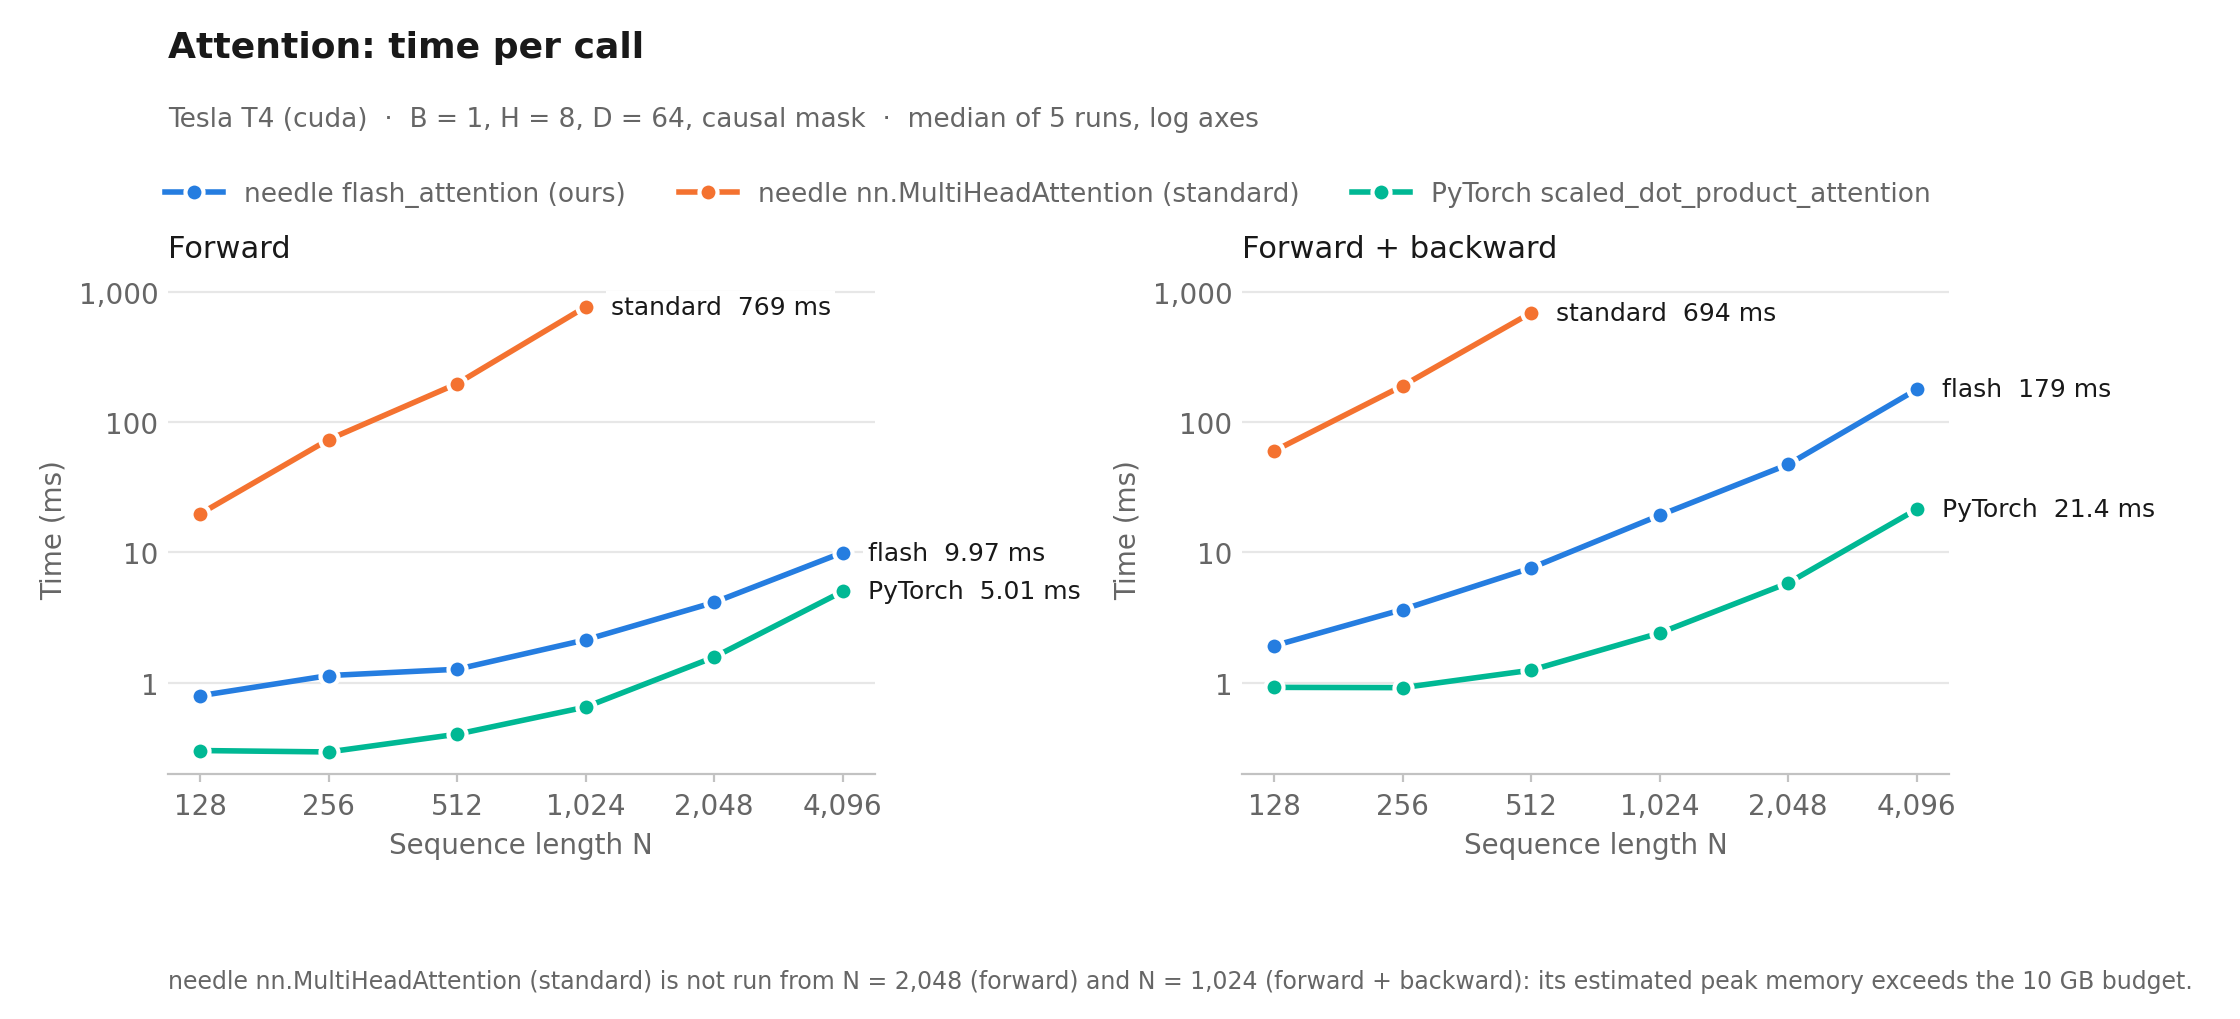

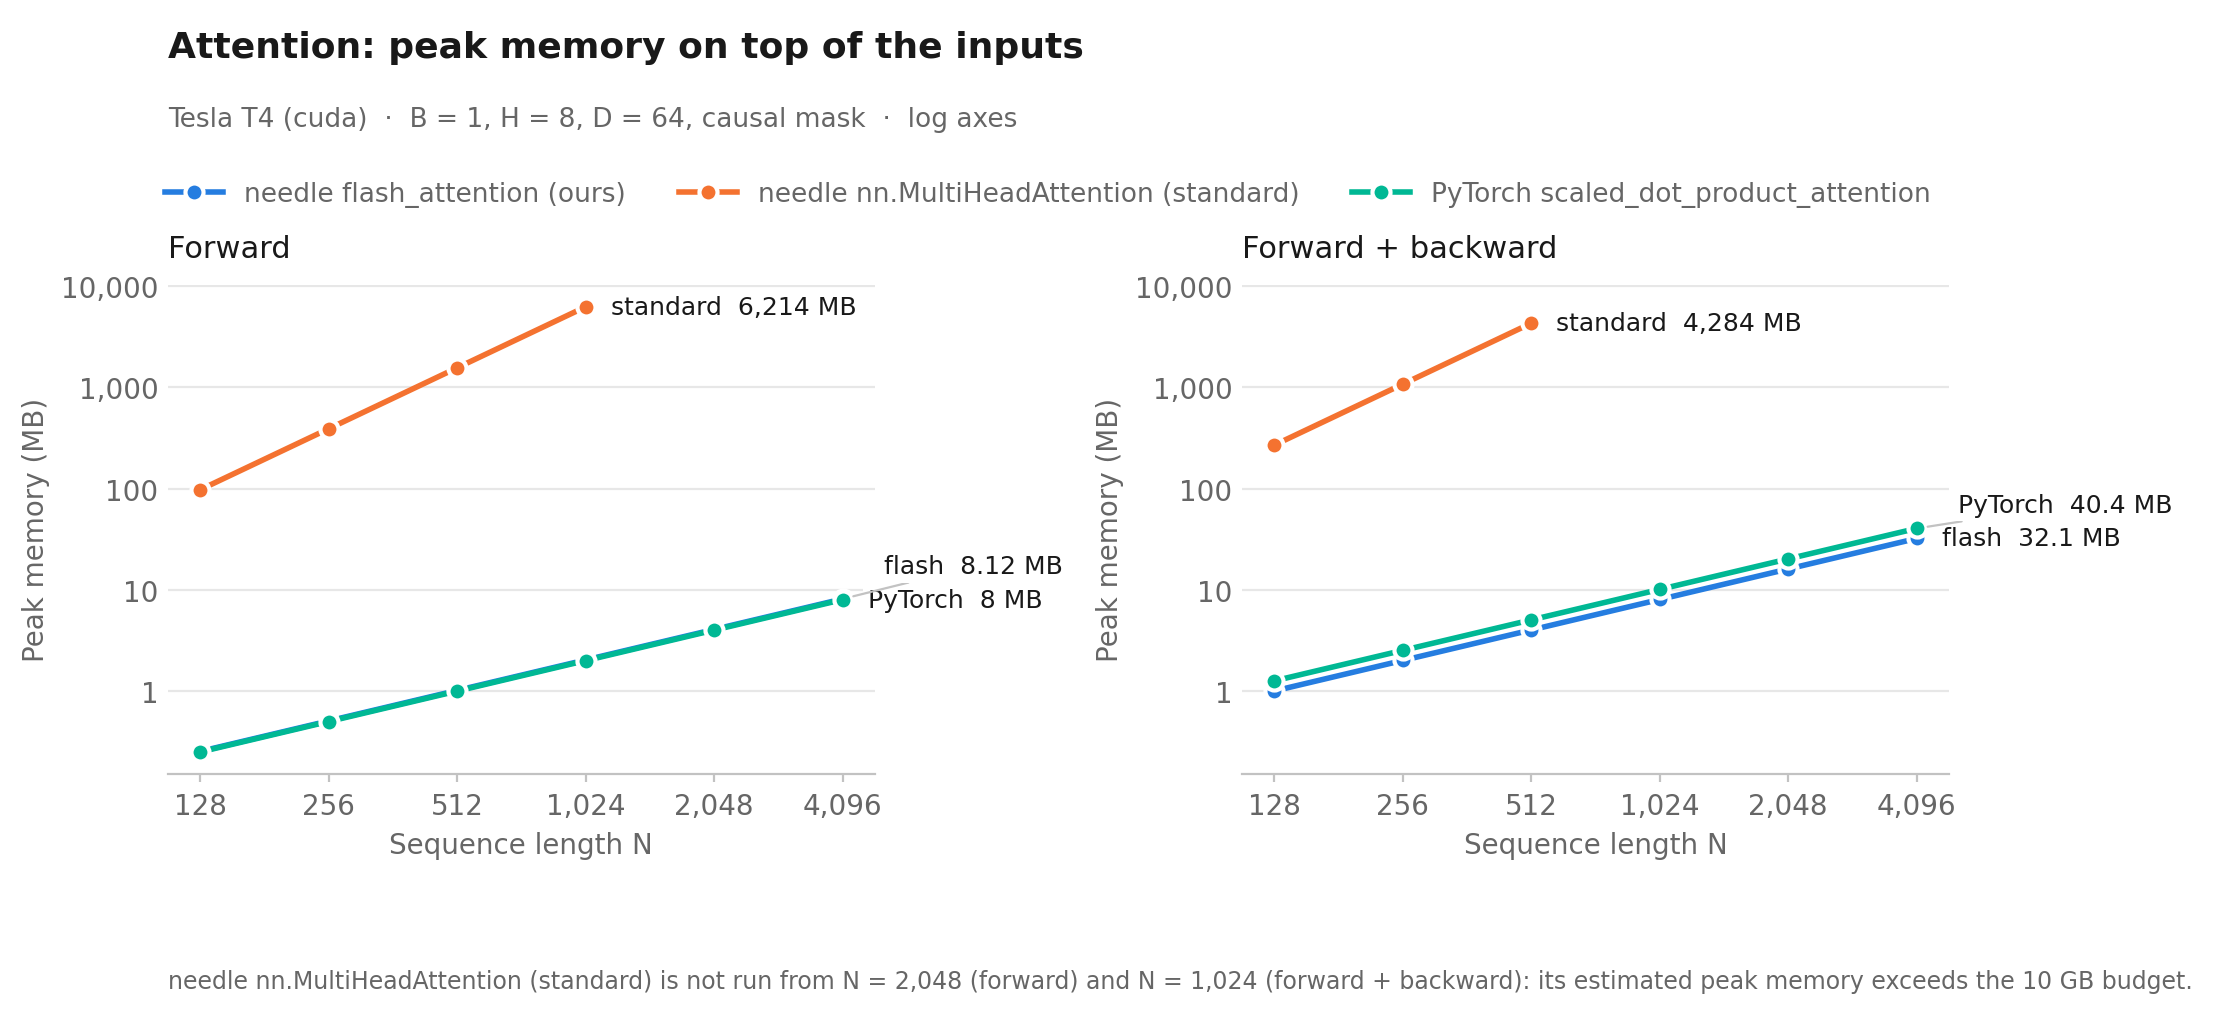

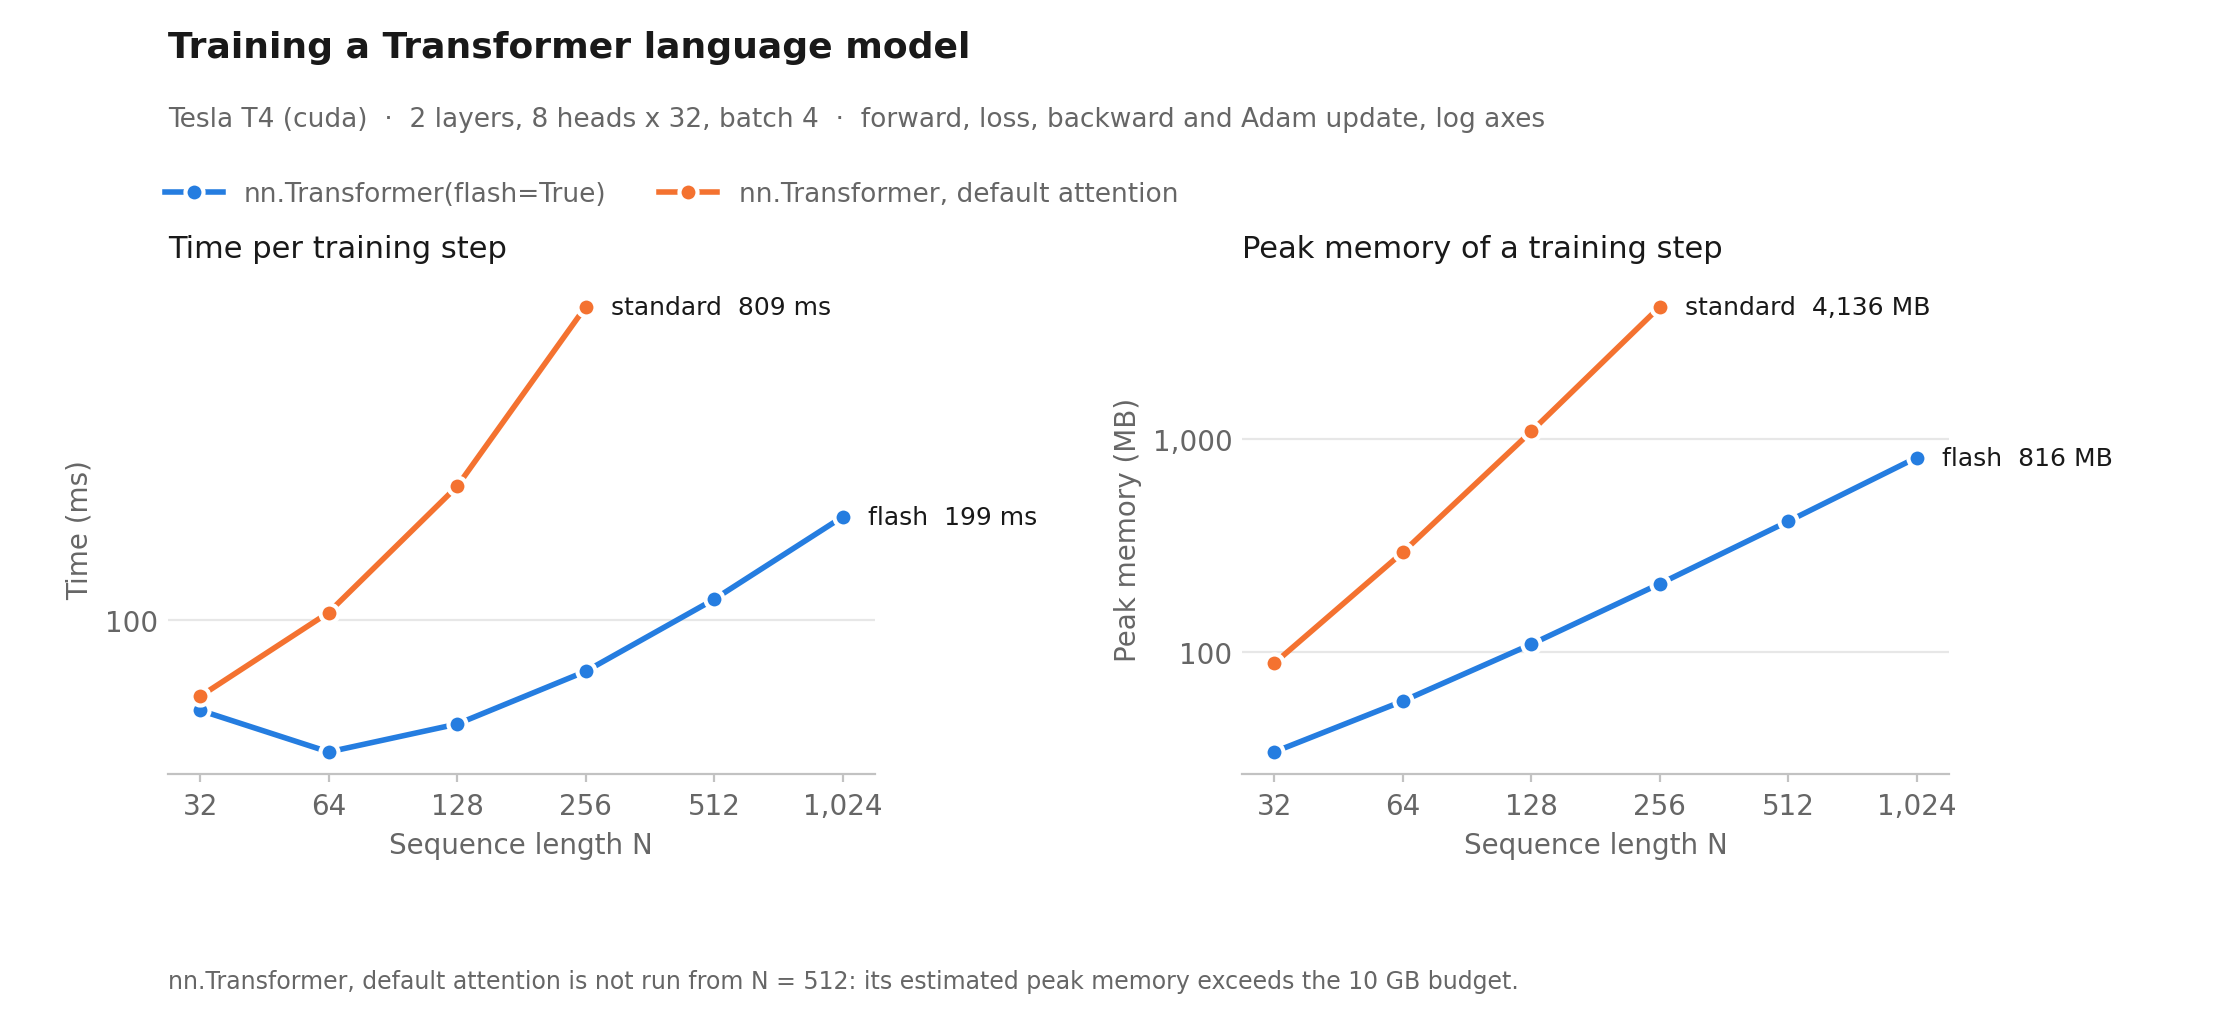

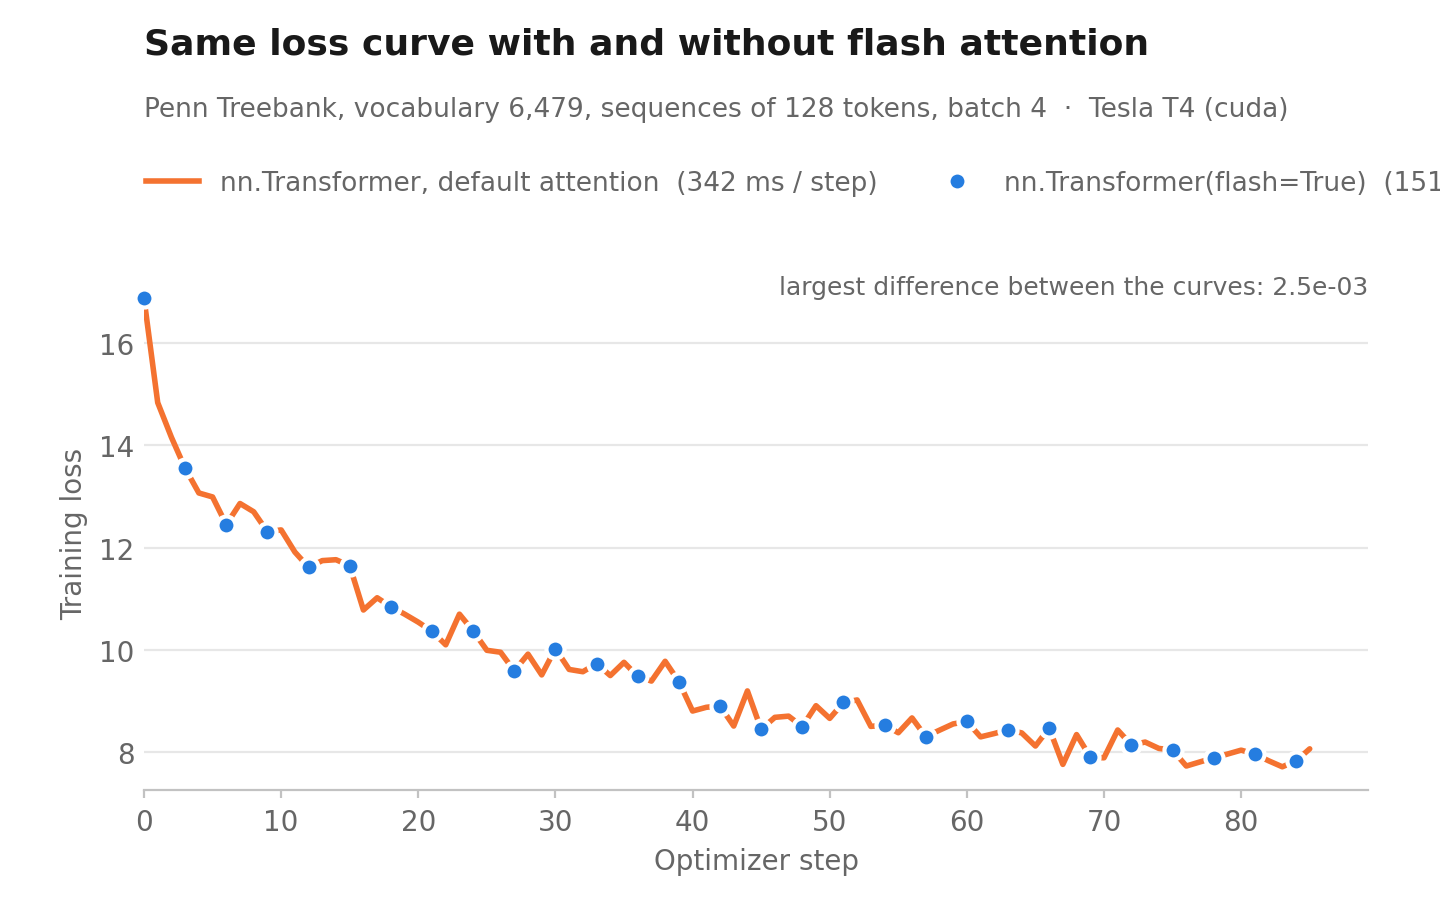

In [8]:
from IPython.display import Image, display

!python apps/plot_flash_benchmarks.py --attention results/attention_cuda.json --transformer results/transformer_cuda.json --out-dir results/figures

for name in ["attention_time", "attention_memory", "transformer_step", "transformer_loss"]:
    display(Image(filename=f"results/figures/{name}.png", width=950))

## 9. Optional: the same benchmarks on the CPU backend

Not needed for the GPU results. Colab's CPU is slow and has about 12 GB of memory, so this uses
shorter sequences and the default 4 GB budget; it takes a few minutes.

In [ ]:
RUN_CPU_BENCHMARKS = False  # set to True to run

if RUN_CPU_BENCHMARKS:
    !python apps/bench_flash_attention.py --device cpu --causal --lens 128 256 512 1024 2048 --repeats 3 --out results/attention_cpu.json
    !python apps/bench_flash_transformer.py --device cpu --lens 32 64 128 256 --ptb-dir data/ptb --train-steps 60 --train-seq-len 64 --out results/transformer_cpu.json
    !python apps/plot_flash_benchmarks.py --attention results/attention_cpu.json --transformer results/transformer_cpu.json --out-dir results/figures_cpu
    for name in ["attention_time", "attention_memory", "transformer_step", "transformer_loss"]:
        display(Image(filename=f"results/figures_cpu/{name}.png", width=950))

## 10. Download the results

`results.zip` holds the JSON records (every number in the tables above) and the figures.

In [9]:
from google.colab import files

!rm -f /content/results.zip && zip -qr /content/results.zip results
files.download("/content/results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>